In [3]:
# Step 1: Upload the resume CSV and inspect it
import pandas as pd
from google.colab import files

# Opens a file picker; choose the resume CSV (e.g. Resume.csv)
uploaded = files.upload()
file_name = list(uploaded.keys())[0]  # name of the uploaded file

# Read the CSV (latin-1 avoids encoding errors on some files)
df = pd.read_csv(file_name, encoding="latin-1")

print("Shape (rows, columns):", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types and missing values:")
df.info()

# Duplicates and missing values
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

# ---------- Find the category (label) column: text with few unique values ----------
obj_cols = df.select_dtypes(include="object").columns
cat_candidates = [c for c in obj_cols if df[c].nunique() <= 60]
for c in cat_candidates:
    print(f"\n--- {c} ({df[c].nunique()} unique values) ---")
    print(df[c].value_counts())

# ---------- Find the resume text column: longest text, not HTML ----------
avg_len = {c: df[c].astype(str).str.len().mean() for c in obj_cols}
looks_html = {c: df[c].astype(str).str.contains("<div|<span|<p>", regex=True).mean() > 0.5 for c in obj_cols}
print("\nAverage text length per column (and whether it looks like HTML):")
for c, l in sorted(avg_len.items(), key=lambda x: -x[1]):
    print(f"  {c}: {l:.0f} characters | HTML-like: {looks_html[c]}")

plain_cols = [c for c in obj_cols if not looks_html[c]]
text_col = max(plain_cols, key=lambda c: avg_len[c])
print("\nLikely resume text column:", text_col)

# ---------- Text length stats ----------
words = df[text_col].astype(str).str.split().str.len()
print("\nWords per resume: min", words.min(), "| median", int(words.median()), "| max", words.max())
print("Resumes under 50 words:", (words < 50).sum())
print("Duplicate resume texts:", df[text_col].duplicated().sum())

# ---------- Show a SHORT snippet only (resumes may contain personal details) ----------
print("\nOne sample (first 300 characters only):")
print(str(df[text_col].iloc[0])[:300])

Saving Resume.csv to Resume.csv
Shape (rows, columns): (2484, 4)

Columns: ['ID', 'Resume_str', 'Resume_html', 'Category']

Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ID           2484 non-null   int64 
 1   Resume_str   2484 non-null   object
 2   Resume_html  2484 non-null   object
 3   Category     2484 non-null   object
dtypes: int64(1), object(3)
memory usage: 77.8+ KB

Missing values per column:
ID             0
Resume_str     0
Resume_html    0
Category       0
dtype: int64

Duplicate rows: 0

--- Category (24 unique values) ---
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  11

In [4]:
import re
import nltk
import pandas as pd
from functools import lru_cache
from collections import Counter
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

# Safety check: Step 1 must have created 'df'
assert "df" in globals(), "Run Step 1 first (the 'df' table is missing)."

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

# ---------- 1) Keep only the columns we need (drop the HTML copy) ----------
data = df[["ID", "Resume_str", "Category"]].rename(columns={"Resume_str": "raw_text"}).copy()
n_start = len(data)

# ---------- 2) Remove empty/very short and duplicate resumes ----------
data["raw_words"] = data["raw_text"].astype(str).str.split().str.len()
data = data[data["raw_words"] >= 50]                        # too short to score fairly
n_short = n_start - len(data)

# Texts that appear under more than one category are ambiguous: drop them all
labels_per_text = data.groupby("raw_text")["Category"].nunique()
conflicting = labels_per_text[labels_per_text > 1].index
data = data[~data["raw_text"].isin(conflicting)]
data = data.drop_duplicates(subset="raw_text").reset_index(drop=True)  # keep one copy
print(f"Start: {n_start} | dropped short: {n_short} | final: {len(data)}")

Start: 2484 | dropped short: 1 | final: 2481


In [5]:
def get_title(text):
    # First non-empty line is usually the job title in this dataset
    for line in str(text).splitlines():
        if line.strip():
            return line.strip()[:80]
    return ""
data["title"] = data["raw_text"].apply(get_title)

In [6]:
def make_skill_text(text):
    t = str(text).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)      # remove URLs
    t = re.sub(r"\S+@\S+", " ", t)               # remove email addresses
    t = re.sub(r"\s+", " ", t)                   # collapse whitespace
    return t.strip()
data["skill_text"] = data["raw_text"].apply(make_skill_text)

In [7]:
tokenizer = RegexpTokenizer(r"[a-z]+")           # letters only
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))
noise_words = {
    # placeholders and section headers that appear in almost every resume
    "company", "name", "city", "state", "summary", "highlights", "experience",
    "education", "training", "skills", "skill", "professional", "profile",
    "objective", "qualification", "accomplishment", "current", "responsible",
    "including", "include", "worked", "work", "ability", "able", "well",
    "january", "february", "march", "april", "may", "june", "july", "august",
    "september", "october", "november", "december", "present", "year", "month",
}
stop_words |= noise_words

@lru_cache(maxsize=None)              # cache: each unique word is lemmatized only once
def lemma(word):
    return lemmatizer.lemmatize(word)

def make_clean_text(text):
    tokens = tokenizer.tokenize(str(text).lower())
    tokens = [lemma(t) for t in tokens if t not in stop_words and len(t) >= 2]
    return " ".join(tokens)

data["clean_text"] = data["skill_text"].apply(make_clean_text)   # takes about 30-60 seconds
data["clean_words"] = data["clean_text"].str.split().str.len()

In [8]:
print("\nWords per resume: raw median", int(data["raw_words"].median()),
      "| cleaned median", int(data["clean_words"].median()))
print("Resumes with fewer than 30 cleaned words:", (data["clean_words"] < 30).sum())

print("\nCategory counts after cleaning (smallest 5):")
print(data["Category"].value_counts().tail(5))

print("\nExample titles (first line) for 3 categories:")
for cat in ["INFORMATION-TECHNOLOGY", "HR", "ACCOUNTANT"]:
    print(f"  {cat}: {list(data.loc[data['Category'] == cat, 'title'].head(3))}")


Words per resume: raw median 759 | cleaned median 503
Resumes with fewer than 30 cleaned words: 0

Category counts after cleaning (smallest 5):
Category
APPAREL          97
DIGITAL-MEDIA    96
AGRICULTURE      63
AUTOMOBILE       36
BPO              22
Name: count, dtype: int64

Example titles (first line) for 3 categories:
  INFORMATION-TECHNOLOGY: ['INFORMATION TECHNOLOGY         Summary     Dedicated  Information Assurance Prof', 'INFORMATION TECHNOLOGY SPECIALIST\tGS11             Experience     07/2004   to  ', 'INFORMATION TECHNOLOGY SUPERVISOR       Summary    Seeking a position as an Info']
  HR: ['HR ADMINISTRATOR/MARKETING ASSOCIATE', 'HR SPECIALIST, US HR OPERATIONS       Summary     Versatile  media professional ', 'HR DIRECTOR       Summary      Over 20 years experience in recruiting,   15 plus']
  ACCOUNTANT: ['ACCOUNTANT       Professional Summary     Current Accountant with the City of Al', 'ACCOUNTANT       Summary      Innovative and energetic Accountant proficient i

In [9]:
print("\nTop 10 words per category:")
for cat in ["INFORMATION-TECHNOLOGY", "HR", "ACCOUNTANT", "CHEF", "DIGITAL-MEDIA", "SALES"]:
    words = Counter(" ".join(data.loc[data["Category"] == cat, "clean_text"]).split())
    print(f"{cat:24s}", [w for w, _ in words.most_common(10)])

# ---------- 8) Show only a SHORT cleaned snippet (avoid printing personal details) ----------
print("\nCleaned snippet (first 200 characters):")
print(data["clean_text"].iloc[0][:200])


Top 10 words per category:
INFORMATION-TECHNOLOGY   ['system', 'management', 'information', 'technology', 'network', 'project', 'support', 'server', 'business', 'data']
HR                       ['employee', 'hr', 'management', 'resource', 'human', 'process', 'benefit', 'new', 'program', 'manager']
ACCOUNTANT               ['accounting', 'account', 'financial', 'report', 'management', 'accountant', 'tax', 'monthly', 'reconciliation', 'statement']
CHEF                     ['food', 'chef', 'kitchen', 'service', 'customer', 'menu', 'management', 'staff', 'culinary', 'quality']
DIGITAL-MEDIA            ['marketing', 'medium', 'digital', 'client', 'management', 'business', 'sale', 'team', 'project', 'customer']
SALES                    ['customer', 'sale', 'service', 'product', 'management', 'store', 'new', 'team', 'business', 'manager']

Cleaned snippet (first 200 characters):
hr administrator marketing associate hr administrator dedicated customer service manager year hospitality customer

In [10]:
import re
import pandas as pd

# Safety check: Step 2 objects must exist
for name in ["data", "make_skill_text", "make_clean_text"]:
    assert name in globals(), f"Run Step 2 first ('{name}' is missing)."

# ---------- 1) Fix title extraction: split on runs of 2+ whitespace characters ----------
def split_title(text):
    parts = re.split(r"\s{2,}|\t", str(text).strip(), maxsplit=2)
    title = parts[0][:80]                       # first segment = job title
    # If the 2nd segment is a short repeated headline, drop it too
    if len(parts) > 2 and len(parts[1]) <= 60:
        body = parts[2]
    else:
        body = " ".join(parts[1:])
    return pd.Series({"title": title, "body_text": body})

data[["title", "body_text"]] = data["raw_text"].apply(split_title)

# Headline-removed versions (used later to check the ranking is not just reading the title)
data["skill_text_nt"] = data["body_text"].apply(make_skill_text)
data["clean_text_nt"] = data["skill_text_nt"].apply(make_clean_text)

In [11]:
print("Title examples (job titles only):")
for cat in ["INFORMATION-TECHNOLOGY", "HR", "ACCOUNTANT", "DIGITAL-MEDIA"]:
    print(f"  {cat}: {list(data.loc[data['Category'] == cat, 'title'].head(4))}")

Title examples (job titles only):
  INFORMATION-TECHNOLOGY: ['INFORMATION TECHNOLOGY', 'INFORMATION TECHNOLOGY SPECIALIST', 'INFORMATION TECHNOLOGY SUPERVISOR', 'INFORMATION TECHNOLOGY INSTRUCTOR']
  HR: ['HR ADMINISTRATOR/MARKETING ASSOCIATE', 'HR SPECIALIST, US HR OPERATIONS', 'HR DIRECTOR', 'HR SPECIALIST']
  ACCOUNTANT: ['ACCOUNTANT', 'ACCOUNTANT', 'ACCOUNTANT', 'ACCOUNTANT']
  DIGITAL-MEDIA: ['DIGITAL MEDIA BUYER', 'DIGITAL MEDIA INTERN', 'DIGITAL MEDIA PRODUCER', 'DIGITAL MEDIA MANAGER']


In [12]:
JOBS = {
    "IT Support & Systems Administrator": {
        "category": "INFORMATION-TECHNOLOGY",
        "description": (
            "We are hiring an IT Support and Systems Administrator to maintain our servers, networks and "
            "end-user technology. You will troubleshoot hardware and software problems through the help desk, "
            "administer Windows Server and Active Directory, manage network infrastructure including LAN, WAN, "
            "TCP/IP, DNS and DHCP, and support Linux systems. You will monitor security with firewalls and VPN, "
            "manage backups and disaster recovery, work with virtualization such as VMware, support cloud "
            "services such as AWS or Azure, write scripts in Python or PowerShell, query SQL databases, and "
            "follow ITIL service management practices."),
        "skills": [
            ("Troubleshooting / help desk", 3, r"troubleshoot\w*|help ?desk|technical support|desktop support|end[- ]user support"),
            ("Networking (LAN/WAN, TCP/IP)", 3, r"network (?:administ\w+|engineer\w*|infrastructure|security|support|monitoring)|lan|wan|tcp/?ip|dns|dhcp|routers?"),
            ("Windows Server / Active Directory", 3, r"active directory|windows server|group policy|exchange server|microsoft exchange"),
            ("Linux / Unix", 2, r"linux|unix|red ?hat|ubuntu"),
            ("Cloud (AWS / Azure)", 2, r"aws|amazon web services|azure|cloud (?:computing|services|infrastructure)"),
            ("Virtualization (VMware / Hyper-V)", 2, r"vmware|hyper-?v|virtuali[sz]ation|virtual machines?"),
            ("Security (firewall / VPN)", 2, r"firewalls?|vpn|information security|cyber ?security|antivirus|intrusion"),
            ("SQL / databases", 2, r"sql|oracle database|databases?"),
            ("Scripting (Python / PowerShell)", 2, r"python|powershell|bash|shell scripting|scripting"),
            ("ITIL / service management", 1, r"itil|servicenow|service now|remedy|ticketing"),
            ("Backup / disaster recovery", 1, r"backups?|disaster recovery"),
        ]},
    "HR Generalist": {
        "category": "HR",
        "description": (
            "We are looking for an HR Generalist to support the full employee lifecycle. You will lead "
            "recruiting and talent acquisition, handle employee relations and conflict resolution, administer "
            "benefits and open enrollment, process payroll, and run new hire onboarding and orientation. You "
            "will maintain employee records in an HRIS such as Workday or ADP, support performance management "
            "and reviews, ensure compliance with labor laws including FMLA and EEO, work on compensation, "
            "deliver training and development programs, and update HR policies and the employee handbook."),
        "skills": [
            ("Recruiting / talent acquisition", 3, r"recruit\w*|talent acquisition|staffing"),
            ("Employee relations", 3, r"employee relations|labor relations|grievances?|disciplinary|conflict resolution"),
            ("Benefits administration", 3, r"benefits?|open enrollment|401\(?k\)?"),
            ("Payroll", 2, r"payroll"),
            ("Onboarding / orientation", 2, r"onboarding|new hire orientation|orientation"),
            ("HRIS systems", 2, r"hris|hr information system|workday|adp|peoplesoft|kronos|ultipro|paycom|successfactors"),
            ("Performance management", 2, r"performance (?:management|reviews?|appraisals?|evaluations?)"),
            ("Compliance / labor law", 2, r"compliance|eeo\w*|fmla|ada|labor laws?|employment law|osha"),
            ("Compensation", 2, r"compensation|salary (?:administration|surveys?)|job evaluation"),
            ("Training & development", 1, r"training and development|learning and development|training programs?|employee training"),
            ("HR policies / handbook", 1, r"(?:hr|company|employee) polic(?:y|ies)|policy development|handbook"),
        ]},
    "Accountant": {
        "category": "ACCOUNTANT",
        "description": (
            "We are hiring an Accountant to manage our daily accounting operations. You will process accounts "
            "payable and accounts receivable, maintain the general ledger and journal entries, perform "
            "reconciliation of bank and balance sheet accounts, and prepare financial statements and financial "
            "reporting under GAAP. You will complete month-end and year-end close, support tax filings, "
            "assist with budgeting and forecasting, support internal and external audits, and work with "
            "accounting software such as QuickBooks, SAP or Oracle and advanced Excel. A CPA is a plus."),
        "skills": [
            ("Accounts payable", 3, r"accounts? payable|ap"),
            ("Accounts receivable", 3, r"accounts? receivable|collections"),
            ("General ledger", 3, r"general ledger|gl|journal entr(?:y|ies)"),
            ("Reconciliation", 3, r"reconcil\w*"),
            ("Financial statements / reporting", 3, r"financial statements?|financial reporting|financial reports?|balance sheets?|income statements?|p&l|profit and loss"),
            ("GAAP", 2, r"gaap|generally accepted accounting"),
            ("Tax", 2, r"tax\w*"),
            ("Budgeting / forecasting", 2, r"budget\w*|forecast\w*|variance analysis"),
            ("Accounting software", 2, r"quickbooks|quick books|sap|oracle|peoplesoft|great plains|sage|netsuite|hyperion"),
            ("Excel", 2, r"excel|vlookup|pivot tables?"),
            ("Month-end / year-end close", 2, r"month[- ]end|year[- ]end|closing (?:the )?books|period[- ]end"),
            ("Audit", 2, r"audit\w*"),
            ("CPA", 1, r"cpa|certified public accountant"),
            ("Payroll", 1, r"payroll"),
        ]},
    "Digital Marketing Specialist": {
        "category": "DIGITAL-MEDIA",
        "description": (
            "We are hiring a Digital Marketing Specialist to grow our online presence. You will manage social "
            "media channels such as Facebook, Twitter and Instagram, run SEO and paid search campaigns, track "
            "results with Google Analytics, and create content including blogs and copywriting. You will run "
            "email marketing campaigns, develop brand and marketing strategy, produce visuals with Adobe tools "
            "such as Photoshop and Illustrator, maintain the website in WordPress or other CMS platforms, "
            "support video production, and work with media and public relations."),
        "skills": [
            ("Social media", 3, r"social media|facebook|twitter|instagram|pinterest|youtube"),
            ("SEO / paid search", 3, r"seo|search engine optimi[sz]ation|sem|ppc|google ads|adwords|search engine marketing"),
            ("Analytics", 3, r"google analytics|analytics|web analytics|omniture|metrics"),
            ("Content creation", 2, r"content (?:creation|development|marketing|strategy|management)|blog\w*|copy ?writing"),
            ("Email marketing", 2, r"email (?:marketing|campaigns?)|newsletters?|mailchimp|constant contact"),
            ("Campaign management", 2, r"campaigns?"),
            ("Brand / marketing strategy", 2, r"brand\w*|marketing (?:strategy|strategies|plans?)"),
            ("Design tools (Adobe)", 2, r"adobe|photoshop|illustrator|indesign|premiere|after effects|final cut"),
            ("Web / CMS", 1, r"wordpress|cms|html|css|web design|web development"),
            ("Video / photo production", 1, r"video\w*|photograph\w*|film\w*"),
            ("Public relations / media", 1, r"public relations|press releases?|media relations"),
        ]},
}

# ---------- 3) Compile patterns (word boundaries) and clean the job descriptions ----------
for role, job in JOBS.items():
    job["compiled"] = [(s, w, re.compile(r"\b(?:" + p + r")\b")) for s, w, p in job["skills"]]
    job["total_weight"] = sum(w for _, w, _ in job["skills"])
    job["jd_clean"] = make_clean_text(job["description"])

def extract_skills(text, role):
    # Return the set of skills from this role's dictionary that appear in the text
    return {s for s, _, rx in JOBS[role]["compiled"] if rx.search(text)}

def skill_score(found, role):
    # Weighted share of the role's skills that were found (0 to 1)
    got = sum(w for s, w, _ in JOBS[role]["compiled"] if s in found)
    return got / JOBS[role]["total_weight"]

# ---------- 4) Extract skills for every resume and every role ----------
found_skills = {}                                  # role -> list of skill sets (one per resume)
for role in JOBS:
    found_skills[role] = [extract_skills(t, role) for t in data["skill_text"]]
    data[f"skill_{role}"] = [skill_score(f, role) for f in found_skills[role]]


In [13]:
print("\nAverage skill score: target category vs all other resumes")
rows = []
for role, job in JOBS.items():
    is_target = data["Category"] == job["category"]
    rows.append({"Role": role, "Target category": job["category"], "Target resumes": int(is_target.sum()),
                 "Avg score (target)": round(data.loc[is_target, f"skill_{role}"].mean(), 3),
                 "Avg score (others)": round(data.loc[~is_target, f"skill_{role}"].mean(), 3)})
print(pd.DataFrame(rows).to_string(index=False))

print("\nSkill coverage: % of target-category resumes vs % of all other resumes")
for role, job in JOBS.items():
    is_target = (data["Category"] == job["category"]).values
    print(f"\n{role}  (target = {job['category']})")
    for s, w, _ in job["compiled"]:
        has = pd.Series([s in f for f in found_skills[role]])
        print(f"  w{w} {s:38s} target {has[is_target].mean()*100:5.1f}% | others {has[~is_target].mean()*100:5.1f}%")


Average skill score: target category vs all other resumes
                              Role        Target category  Target resumes  Avg score (target)  Avg score (others)
IT Support & Systems Administrator INFORMATION-TECHNOLOGY             120               0.424               0.063
                     HR Generalist                     HR             110               0.670               0.134
                        Accountant             ACCOUNTANT             118               0.686               0.135
      Digital Marketing Specialist          DIGITAL-MEDIA              96               0.475               0.100

Skill coverage: % of target-category resumes vs % of all other resumes

IT Support & Systems Administrator  (target = INFORMATION-TECHNOLOGY)
  w3 Troubleshooting / help desk            target  70.0% | others  15.1%
  w3 Networking (LAN/WAN, TCP/IP)           target  55.0% | others   3.9%
  w3 Windows Server / Active Directory      target  47.5% | others   2.0%
  w2 L

In [14]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_auc_score

# Safety check: Step 3 objects must exist
for name in ["data", "JOBS", "extract_skills", "skill_score"]:
    assert name in globals(), f"Run Step 3 first ('{name}' is missing)."

ROLES = list(JOBS.keys())

# Title check from Step 3 (should be short job titles now)
print("Title examples:", list(data.loc[data["Category"] == "HR", "title"].head(4)))

def minmax(x):
    # Rescale scores to 0-1 so the two score types can be blended fairly
    x = np.asarray(x, float)
    rng = x.max() - x.min()
    return (x - x.min()) / rng if rng > 0 else np.zeros_like(x)

# ---------- 1) Score every resume for every role ----------
def score_all(clean_col, skill_col):
    # TF-IDF is fit on the resumes; the job description is transformed with the same vocabulary
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.8,
                          sublinear_tf=True, max_features=60000)
    X = vec.fit_transform(data[clean_col])
    out = {"vec": vec, "X": X}
    for role in ROLES:
        jd = vec.transform([JOBS[role]["jd_clean"]])
        sim = (X @ jd.T).toarray().ravel()            # cosine similarity (rows are L2-normalized)
        sk = np.array([skill_score(extract_skills(t, role), role) for t in data[skill_col]])
        out[role] = {"sim": sim, "skill": sk}
    return out

SC_full = score_all("clean_text", "skill_text")          # resume including its headline
SC_nt = score_all("clean_text_nt", "skill_text_nt")      # headline removed (stricter test)

Title examples: ['HR ADMINISTRATOR/MARKETING ASSOCIATE', 'HR SPECIALIST, US HR OPERATIONS', 'HR DIRECTOR', 'HR SPECIALIST']


In [15]:
def blend(sc, role, alpha):
    # alpha = weight on TF-IDF similarity, (1 - alpha) = weight on skill score
    return alpha * minmax(sc[role]["sim"]) + (1 - alpha) * minmax(sc[role]["skill"])

# ---------- 2) Evaluation: do the top-ranked resumes belong to the matching category? ----------
def evaluate(scores, role):
    is_target = (data["Category"] == JOBS[role]["category"]).values
    order = np.argsort(-scores)
    return {"P@10": is_target[order[:10]].mean(),
            "P@20": is_target[order[:20]].mean(),
            "AUC": roc_auc_score(is_target, scores)}

# Random-guess baseline for precision = share of target resumes in the pool
prevalence = np.mean([(data["Category"] == JOBS[r]["category"]).mean() for r in ROLES])
print(f"\nRandom-guess precision would be about {prevalence:.1%}  (AUC 0.5)")


Random-guess precision would be about 4.5%  (AUC 0.5)


In [16]:
rankers = [("TF-IDF only", 1.0), ("Skills only", 0.0), ("Combined 50/50", 0.5)]
rows, per_role = [], []
for version, sc in [("Full resume", SC_full), ("Headline removed", SC_nt)]:
    for name, alpha in rankers:
        metrics = [evaluate(blend(sc, r, alpha), r) for r in ROLES]
        avg = pd.DataFrame(metrics).mean()
        rows.append({"Version": version, "Ranker": name, "P@10": round(avg["P@10"], 3),
                     "P@20": round(avg["P@20"], 3), "AUC": round(avg["AUC"], 3)})
        if name == "Combined 50/50":
            for r, m in zip(ROLES, metrics):
                per_role.append({"Version": version, "Role": r, "P@10": round(m["P@10"], 2),
                                 "P@20": round(m["P@20"], 2), "AUC": round(m["AUC"], 3)})

print("\nAverage over the 4 roles:")
print(pd.DataFrame(rows).to_string(index=False))
print("\nCombined ranker, per role:")
print(pd.DataFrame(per_role).to_string(index=False))


Average over the 4 roles:
         Version         Ranker  P@10  P@20   AUC
     Full resume    TF-IDF only 0.800 0.788 0.957
     Full resume    Skills only 0.725 0.662 0.930
     Full resume Combined 50/50 0.800 0.750 0.948
Headline removed    TF-IDF only 0.800 0.775 0.955
Headline removed    Skills only 0.675 0.650 0.930
Headline removed Combined 50/50 0.800 0.750 0.947

Combined ranker, per role:
         Version                               Role  P@10  P@20   AUC
     Full resume IT Support & Systems Administrator   0.4  0.50 0.929
     Full resume                      HR Generalist   1.0  0.95 0.972
     Full resume                         Accountant   0.9  0.85 0.970
     Full resume       Digital Marketing Specialist   0.9  0.70 0.922
Headline removed IT Support & Systems Administrator   0.5  0.50 0.928
Headline removed                      HR Generalist   1.0  0.95 0.970
Headline removed                         Accountant   0.9  0.85 0.970
Headline removed       Digital Mark

In [17]:
print("\nBlend weight check (headline removed): share of score from TF-IDF")
sens = []
for alpha in [0.0, 0.25, 0.5, 0.75, 1.0]:
    m = pd.DataFrame([evaluate(blend(SC_nt, r, alpha), r) for r in ROLES]).mean()
    sens.append({"TF-IDF share": alpha, "P@10": round(m["P@10"], 3),
                 "P@20": round(m["P@20"], 3), "AUC": round(m["AUC"], 3)})
print(pd.DataFrame(sens).to_string(index=False))

# ---------- 5) Where do wrong resumes sneak into the top 20? (IDs and categories only) ----------
print("\nCategories of off-target resumes in the top 20 (combined, headline removed):")
for r in ROLES:
    top = np.argsort(-blend(SC_nt, r, 0.5))[:20]
    wrong = data.iloc[top]
    wrong = wrong[wrong["Category"] != JOBS[r]["category"]]["Category"].value_counts().to_dict()
    print(f"  {r}: {wrong if wrong else 'none'}")


Blend weight check (headline removed): share of score from TF-IDF
 TF-IDF share  P@10  P@20   AUC
         0.00 0.675 0.650 0.930
         0.25 0.775 0.712 0.940
         0.50 0.800 0.750 0.947
         0.75 0.775 0.775 0.953
         1.00 0.800 0.775 0.955

Categories of off-target resumes in the top 20 (combined, headline removed):
  IT Support & Systems Administrator: {'CONSULTANT': 5, 'ADVOCATE': 1, 'DIGITAL-MEDIA': 1, 'BPO': 1, 'HEALTHCARE': 1, 'ENGINEERING': 1}
  HR Generalist: {'ARTS': 1}
  Accountant: {'FINANCE': 3}
  Digital Marketing Specialist: {'PUBLIC-RELATIONS': 2, 'SALES': 1, 'APPAREL': 1, 'ARTS': 1, 'CONSULTANT': 1}


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from google.colab import files

# Safety check: earlier steps must have run
for name in ["data", "JOBS", "SC_full", "ROLES", "blend", "extract_skills",
             "skill_score", "make_skill_text", "make_clean_text"]:
    assert name in globals(), f"Run earlier steps first ('{name}' is missing)."

ALPHA = 0.5                                      # 50% TF-IDF similarity + 50% skill score
vec, X = SC_full["vec"], SC_full["X"]            # TF-IDF vectorizer and resume matrix
feature_names = np.array(vec.get_feature_names_out())

# ---------- 1) Final combined score for every resume and role ----------
for role in ROLES:
    data[f"combined_{role}"] = blend(SC_full, role, ALPHA)

# ---------- 2) Explain one candidate: matched skills, missing skills, shared key terms ----------
def explain_candidate(idx, role, n_terms=6):
    found = extract_skills(data.loc[idx, "skill_text"], role)
    matched = sorted([(s, w) for s, w, _ in JOBS[role]["compiled"] if s in found], key=lambda x: -x[1])
    missing = sorted([(s, w) for s, w, _ in JOBS[role]["compiled"] if s not in found], key=lambda x: -x[1])
    # Terms contributing most to the similarity = resume TF-IDF weight x job-description TF-IDF weight
    jd = vec.transform([JOBS[role]["jd_clean"]])
    contrib = X[idx].multiply(jd).tocoo()
    top = np.argsort(-contrib.data)[:n_terms]
    terms = [feature_names[contrib.col[k]] for k in top]
    return matched, missing, terms

def fmt(skills):
    return ", ".join(f"{s} (w{w})" for s, w in skills) if skills else "none"

# ---------- 3) Top 3 candidates per role with explanations (IDs only, no resume text) ----------
for role in ROLES:
    order = np.argsort(-data[f"combined_{role}"].values)
    print(f"\n==================== {role} ====================")
    for rank, i in enumerate(order[:3], 1):
        matched, missing, terms = explain_candidate(i, role)
        print(f"#{rank} | ID {data.loc[i, 'ID']} | {data.loc[i, 'Category']} | combined {data.loc[i, f'combined_{role}']:.2f} "
              f"(similarity {SC_full[role]['sim'][i]:.2f}, skills {SC_full[role]['skill'][i]:.2f})")
        print("   Matched skills:", fmt(matched))
        print("   Missing skills:", fmt(missing))
        print("   Key shared terms:", ", ".join(terms))


==================== IT Support & Systems Administrator ====================
#1 | ID 10089434 | INFORMATION-TECHNOLOGY | combined 1.00 (similarity 0.24, skills 0.96)
   Matched skills: Troubleshooting / help desk (w3), Networking (LAN/WAN, TCP/IP) (w3), Windows Server / Active Directory (w3), Linux / Unix (w2), Cloud (AWS / Azure) (w2), Virtualization (VMware / Hyper-V) (w2), Security (firewall / VPN) (w2), SQL / databases (w2), Scripting (Python / PowerShell) (w2), Backup / disaster recovery (w1)
   Missing skills: ITIL / service management (w1)
   Key shared terms: azure, powershell, server, active directory, vmware, backup
#2 | ID 44115326 | ADVOCATE | combined 0.91 (similarity 0.20, skills 0.96)
   Matched skills: Troubleshooting / help desk (w3), Networking (LAN/WAN, TCP/IP) (w3), Windows Server / Active Directory (w3), Linux / Unix (w2), Cloud (AWS / Azure) (w2), Virtualization (VMware / Hyper-V) (w2), Security (firewall / VPN) (w2), SQL / databases (w2), Scripting (Python / Pow

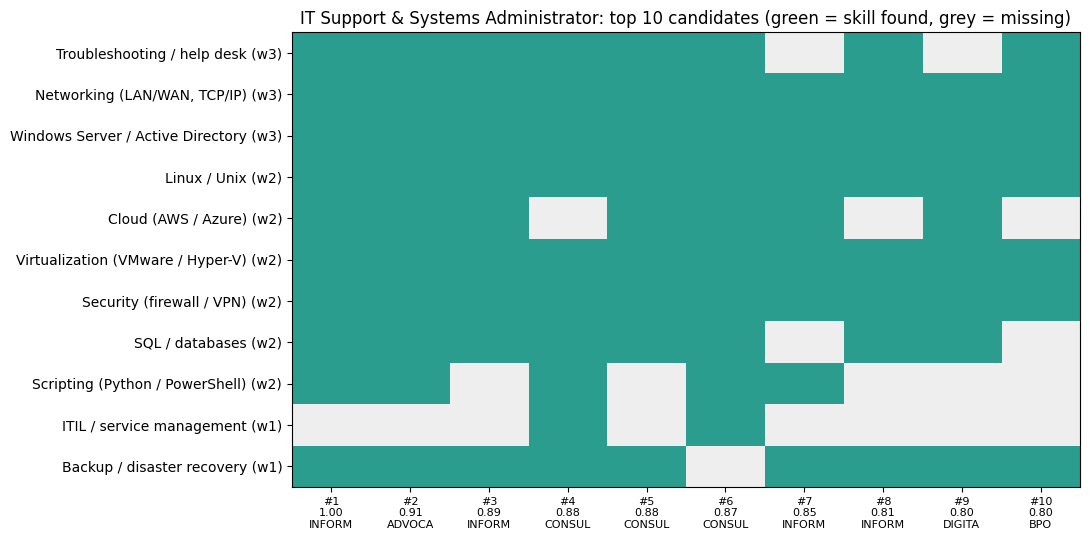

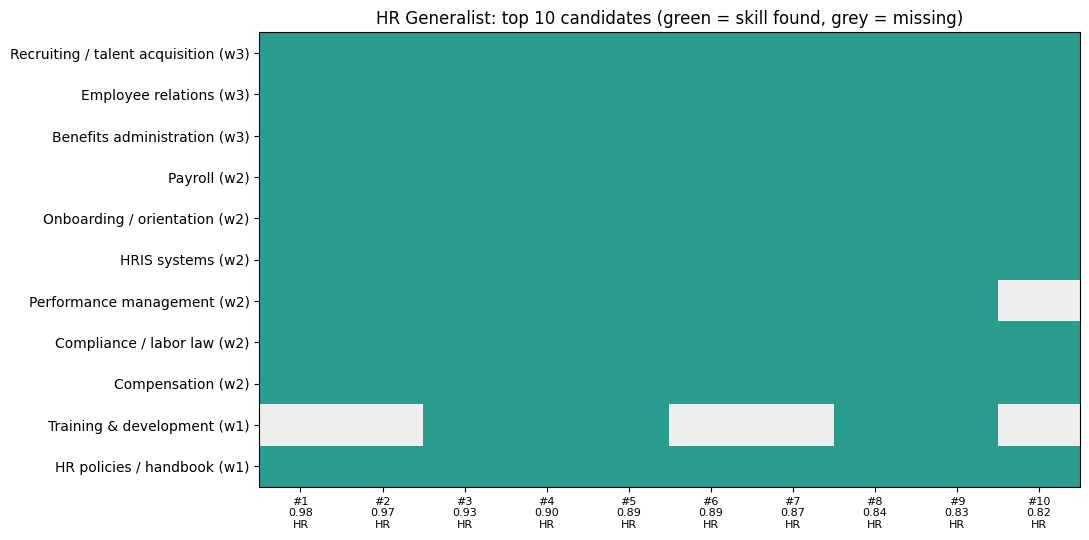

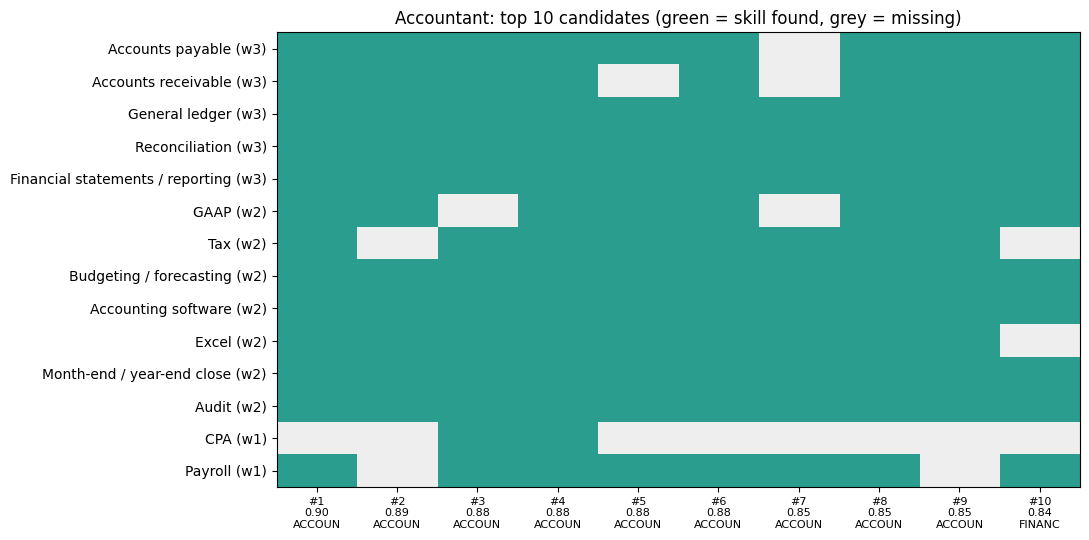

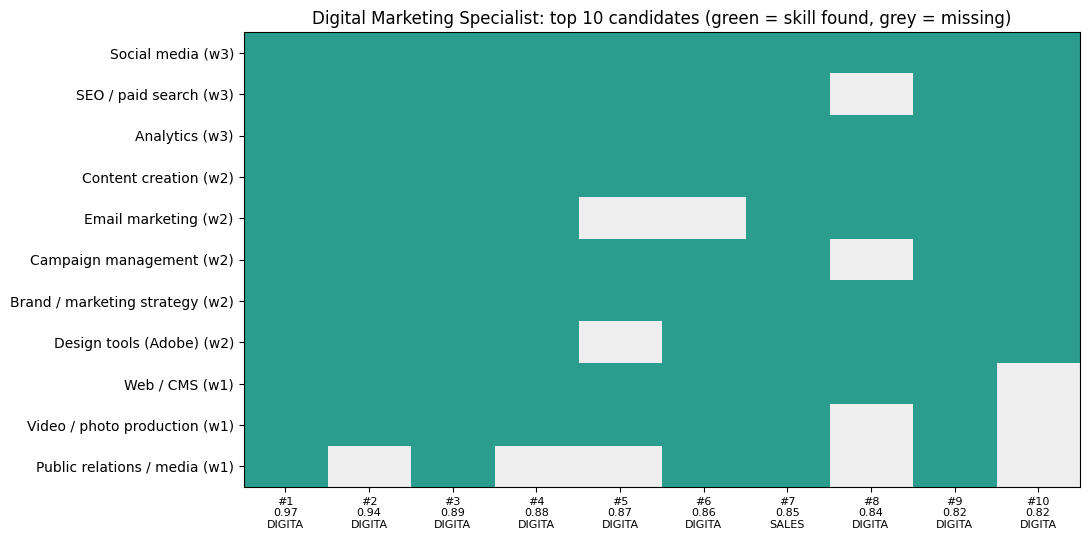

In [19]:
def plot_candidates(role, top_n=10):
    order = np.argsort(-data[f"combined_{role}"].values)[:top_n]
    skills = sorted(JOBS[role]["skills"], key=lambda s: -s[1])           # must-haves first
    M = np.array([[1 if s in extract_skills(data.loc[i, "skill_text"], role) else 0
                   for s, _, _ in skills] for i in order])
    fig, ax = plt.subplots(figsize=(11, 5.5))
    ax.imshow(M.T, cmap=ListedColormap(["#eeeeee", "#2a9d8f"]), aspect="auto")
    ax.set_yticks(range(len(skills)))
    ax.set_yticklabels([f"{s} (w{w})" for s, w, _ in skills])
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"#{k+1}\n{data.loc[i, f'combined_{role}']:.2f}\n{data.loc[i, 'Category'][:6]}"
                        for k, i in enumerate(order)], fontsize=8)
    ax.set_title(f"{role}: top {top_n} candidates (green = skill found, grey = missing)")
    plt.tight_layout()
    fname = "candidates_" + role.replace(" & ", "_and_").replace(" ", "_") + ".png"
    plt.savefig(fname, dpi=150)
    plt.show()
    return fname

png_files = [plot_candidates(role) for role in ROLES]

In [20]:
def screen_resume(text, role):
    skill_t = make_skill_text(text)
    found = extract_skills(skill_t, role)
    sk = skill_score(found, role)
    jd = vec.transform([JOBS[role]["jd_clean"]])
    sim = float((vec.transform([make_clean_text(skill_t)]) @ jd.T).toarray()[0, 0])
    # Scale with the same min/max as the resume pool so scores are comparable
    ps, pk = SC_full[role]["sim"], SC_full[role]["skill"]
    sim_s = float(np.clip((sim - ps.min()) / (ps.max() - ps.min()), 0, 1))
    sk_s = float(np.clip((sk - pk.min()) / (pk.max() - pk.min()), 0, 1))
    combined = ALPHA * sim_s + (1 - ALPHA) * sk_s
    pool = data[f"combined_{role}"].values
    missing = sorted([(s, w) for s, w, _ in JOBS[role]["compiled"] if s not in found], key=lambda x: -x[1])
    return {"role": role, "combined_score": round(combined, 2),
            "better_than_pct_of_pool": round((pool < combined).mean() * 100, 1),
            "skills_found": sorted(found), "missing_skills": [f"{s} (w{w})" for s, w in missing]}

strong = ("Systems Administrator with 6 years of experience. Administered Windows Server and Active Directory, "
          "configured firewalls and VPN, managed VMware virtual machines, handled backups and disaster recovery, "
          "supported Linux servers, resolved help desk tickets, wrote PowerShell scripts, managed LAN/WAN and DHCP.")
weak = ("Retail associate with customer service experience. Handled cash register, stocked shelves and "
        "helped customers. Used basic Excel for inventory lists.")
print("\n==================== DEMO: screening new resumes for IT role ====================")
for label, text in [("Strong IT resume", strong), ("Unrelated resume", weak)]:
    print(f"\n{label}:", screen_resume(text, "IT Support & Systems Administrator"))

# ---------- 6) Save results (IDs and scores only, no resume text) ----------
rows = []
for role in ROLES:
    order = np.argsort(-data[f"combined_{role}"].values)
    for rank, i in enumerate(order[:50], 1):
        matched, missing, _ = explain_candidate(i, role, n_terms=0)
        rows.append({"role": role, "rank": rank, "resume_id": data.loc[i, "ID"],
                     "category": data.loc[i, "Category"],
                     "combined_score": round(data.loc[i, f"combined_{role}"], 3),
                     "tfidf_similarity": round(SC_full[role]["sim"][i], 3),
                     "skill_score": round(SC_full[role]["skill"][i], 3),
                     "matched_skills": "; ".join(s for s, _ in matched),
                     "missing_skills": "; ".join(s for s, _ in missing)})
pd.DataFrame(rows).to_csv("ranked_candidates_top50.csv", index=False)
print("\nSaved: ranked_candidates_top50.csv +", len(png_files), "comparison charts")

for f in ["ranked_candidates_top50.csv"] + png_files:
    files.download(f)


==================== DEMO: screening new resumes for IT role ====================

Strong IT resume: {'role': 'IT Support & Systems Administrator', 'combined_score': 0.91, 'better_than_pct_of_pool': np.float64(100.0), 'skills_found': ['Backup / disaster recovery', 'Linux / Unix', 'Networking (LAN/WAN, TCP/IP)', 'Scripting (Python / PowerShell)', 'Security (firewall / VPN)', 'Troubleshooting / help desk', 'Virtualization (VMware / Hyper-V)', 'Windows Server / Active Directory'], 'missing_skills': ['Cloud (AWS / Azure) (w2)', 'SQL / databases (w2)', 'ITIL / service management (w1)']}

Unrelated resume: {'role': 'IT Support & Systems Administrator', 'combined_score': 0.01, 'better_than_pct_of_pool': np.float64(5.9), 'skills_found': [], 'missing_skills': ['Troubleshooting / help desk (w3)', 'Networking (LAN/WAN, TCP/IP) (w3)', 'Windows Server / Active Directory (w3)', 'Linux / Unix (w2)', 'Cloud (AWS / Azure) (w2)', 'Virtualization (VMware / Hyper-V) (w2)', 'Security (firewall / VPN) (w2)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>